# Anchor cross-attention: add evidence without replacing the anchor

This notebook asks whether an auxiliary representation helps more when attention updates a selected anchor through an explicit skip connection. The anchor is chosen from seed-zero validation evidence and fixed across three training seeds. The models compare no skip, an ungated skip, sequence sigmoid gates and position sigmoid gates, following [the advisor's plan, A.5](../../docs/Biological_Fusion_Plan.docx).

The default diagnostic panel is CoV-Vac degradation and E. coli protein-production class, with both the original and mRNA-FM encoder combinations. Attention here is a controlled adaptation on frozen BLF inputs; it is not a full IsoFormer reproduction. The [encoder-swap notebook](encoder_swaps.ipynb) supplies the preceding comparison, while [gate diagnostics](gate_diagnostics.ipynb) tests whether normalization and gate granularity matter before attributing a gain to cross-attention.

All current inputs use the same codon grid. If validation selected a native nucleotide-resolution single, its new projected anchor is a changed representation. A freshly fitted projected-anchor-only control measures that consequence. An exact zero update preserves this projected anchor's features, not the previous native model's predictions. Existing results remain separate evidence.

Newton completed 72 fits and saved diagnostics for the 48 fits with attention updates. Both encoder combinations were tested on CoV-Vac and E. coli across training seeds 0, 1 and 2. [Read the three-seed comparison](#Read-the-saved-comparison) or [inspect the diagnostic distributions](#Read-gate-variation-and-contribution-scales).

---

## Setup

To refresh this notebook from the returned results, keep `READ_SAVED_RESULTS = True`, leave `RUN_TRAINING`, `RUN_DIAGNOSTICS`, `RUN_ANALYSIS` and `RUN_PARAMETER_PREVIEW` set to `False`, then use **Run All** and **Save**. The CPU reader verifies the files listed in the saved reports and redraws their tables and figures. `BENCHMARK = None` includes both benchmarks. The [root README](../../README.md#notebook-dependencies) lists the notebook dependencies.

In [1]:
# Standard-library paths, immutable configuration updates and saved JSON records.
from dataclasses import asdict, replace
import hashlib
import json
from pathlib import Path
import sys

# Data tables and plotting; import NumPy before PyTorch in the Windows environment.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import torch

In [2]:
working_dir = Path.cwd().resolve()
for parent in (working_dir, *working_dir.parents):
    if (parent / "shared_code").is_dir():
        CODE_DIR = parent
        break
    if (parent / "Code" / "shared_code").is_dir():
        CODE_DIR = parent / "Code"
        break
else:
    raise FileNotFoundError("Start this notebook from within the repository.")
if str(CODE_DIR) not in sys.path:
    sys.path.insert(0, str(CODE_DIR))

from shared_code import datasets
from shared_code.fusion import controlled_experiment as experiment, controlled_models
from shared_code.fusion import correction_experiment, run_identity, study_inputs
from shared_code.fusion import study_references, study_selection, token_embeddings, train

### Execution, comparison settings and locations

The launcher injects one benchmark, seed, verified GPU and output location after the settings cell. CoV-Vac and E. coli are the default panel. Fungal expression is a selectable follow-up; grouped stability needs its own compatible grouped references and remains a held expansion. The source inputs and returned Newton results are never overwritten.

In [3]:
READ_SAVED_RESULTS = True
RUN_TRAINING = False
RUN_ANALYSIS = False
RUN_DIAGNOSTICS = False
RUN_PARAMETER_PREVIEW = False  # Explicit CPU construction from declared shapes; no data or weights.

# The prepared launcher selects one benchmark and one training seed per job.
BENCHMARKS = ("cov_vac_degradation", "ecoli_proteins")
BENCHMARK = None
SEED = 0
TRAINING_SEEDS = (0, 1, 2)
SELECTION_SEED = 0
BOOTSTRAP_DRAWS = 2000
BOOTSTRAP_SEED = 0
BUNDLES = {
    "original": {"dna": "ntv2_100m", "rna": "rnafm", "prot": "esm2_8m"},
    "mrnafm": {"dna": "ntv2_100m", "rna": "mrnafm", "prot": "esm2_8m"},
}

# Retained BLF training budget; these are choices, not newly tuned settings.
BASE_CONFIG = train.TrainConfig(
    lr=3e-5, weight_decay=1e-5, batch_size=32, max_epochs=500,
    early_stopping_patience=20, plateau_patience=5,
    channels=100, tconv="equation", entropy_lambda=0.0, seed=0,
)
CONFIG = replace(BASE_CONFIG, seed=SEED)
PROJECTION_WIDTH = 600
# Derived before outcomes: two auxiliary attention modules plus their joint gates.
CONTROL_HIDDEN_WIDTH = controlled_models.attention_control_budget(PROJECTION_WIDTH, 3)["hidden_width"]
SCORER_WIDTH = 100  # Legacy BLF setting; inactive for every attention gate in this panel.
PROJECTION_ACTIVATION = "tanh"
PROJECTION_NORM = "none"
SHARED_SCORER = False
TEMPERATURE_RANGE = (0.02, 20.0)
CONTROL_BOTTLENECK = 150  # Retained; no longer a parameter match after the joint-linear gate correction.
N_HEADS = 4
ATTENTION_DROPOUT = 0.1
UPDATE_NORM = "none"  # Nothing renormalizes the anchor after a zero auxiliary update.

DATA_ROOT = CODE_DIR.parent / "datasets"
CACHE_ROOT = CODE_DIR / "stage3" / "embeddings"
REFERENCE_ROOT = CODE_DIR / "stage4" / "results" / "newton_h100_seeds012"
GROUPED_SPLIT_PATH = CODE_DIR / "stage4" / "results" / "grouped_stability_v1" / "split.json"
RESULTS_ROOT = CODE_DIR / "stage4" / "results" / "anchor_cross_attention_v1"
DEVICE = "cpu"  # Reading saved records does not inspect or allocate a GPU.
PRODUCER = None  # The launcher supplies observed execution provenance, not an inferred host.

In [4]:
if CONTROL_HIDDEN_WIDTH != 1203:
    raise ValueError("The declared attention-budget control uses width 1203 at projection width 600.")
if RUN_PARAMETER_PREVIEW and (RUN_TRAINING or RUN_ANALYSIS or RUN_DIAGNOSTICS):
    raise ValueError("Parameter preview is a separate CPU-only operation.")
if (PROJECTION_WIDTH, SCORER_WIDTH, PROJECTION_ACTIVATION, PROJECTION_NORM,
        SHARED_SCORER, tuple(TEMPERATURE_RANGE)) != (600, 100, "tanh", "none", False, (0.02, 20.0)):
    raise ValueError("This retained reference panel uses the declared BLF projection/scorer settings.")
if TRAINING_SEEDS != (0, 1, 2) or SELECTION_SEED != 0:
    raise ValueError("This panel fixes training seeds 0/1/2 and selection seed 0.")
if RUN_TRAINING == READ_SAVED_RESULTS:
    raise ValueError("Choose saved reading or explicit training, not both/neither.")
if RUN_TRAINING and (RUN_ANALYSIS or RUN_DIAGNOSTICS):
    raise ValueError("Analysis and diagnostic inference are separate from fitting jobs.")
if RUN_TRAINING:
    if BENCHMARK not in BENCHMARKS or SEED not in TRAINING_SEEDS:
        raise ValueError("Select one declared benchmark and training seed for this job.")
    if DEVICE != "cuda" or not torch.cuda.is_available():
        raise RuntimeError("Training requires the verified Newton CUDA device; no CPU fallback.")
    if not isinstance(PRODUCER, dict) or not PRODUCER:
        raise ValueError("Training requires the launcher's observed producer record.")
if RUN_DIAGNOSTICS and (not isinstance(PRODUCER, dict) or not PRODUCER):
    raise ValueError("Explicit best-weight inference requires its own producer record.")
if RUN_DIAGNOSTICS and (BENCHMARK not in BENCHMARKS or SEED not in TRAINING_SEEDS):
    raise ValueError("Select one declared benchmark and seed for diagnostic inference.")
if set(BENCHMARKS) - {"cov_vac_degradation", "ecoli_proteins", "fungal_expression"}:
    raise ValueError("Grouped stability requires a separate grouped-reference adapter; do not reuse supplied-split controls.")
ACTIVE_BENCHMARKS = (BENCHMARK,) if BENCHMARK is not None else BENCHMARKS
if not set(ACTIVE_BENCHMARKS) <= set(BENCHMARKS):
    raise ValueError("The requested benchmark is outside the declared panel.")
CONFIG = replace(BASE_CONFIG, seed=SEED)
if RUN_TRAINING:
    print(f"Explicit {BENCHMARK} seed {SEED} fitting job on {DEVICE}.")
elif RUN_DIAGNOSTICS:
    print(f"Explicit {BENCHMARK} seed {SEED} best-weight diagnostic inference on {DEVICE}.")
elif RUN_ANALYSIS:
    print("Explicit CPU analysis of saved predictions and diagnostics; no fitting or inference.")
else:
    print("Saved-result reading; no fit, inference or statistical analysis is enabled.")

Saved-result reading; no fit, inference or statistical analysis is enabled.


---

## What each comparison changes

All auxiliary streams read the same projected anchor queries. Ordinary attention sums auxiliary updates without an anchor skip. The skip variant adds those updates to the anchor. Following section A.5 of the advisor protocol, the gated variants form $u_t=[H_t^a;A_{m_1,t};A_{m_2,t}]$ and score each auxiliary with $\alpha_{m,t}=\sigma(c_m^\top u_t+\beta_m)$. Both gates can see both updates. The sequence comparator applies the same linear scorer to the masked sequence mean of $u_t$; the position comparator applies it at each real query position.

This joint-linear scorer replaces the earlier prepared nonlinear gate that saw only the anchor and its own auxiliary update. Independent attention modules, projection width, heads and dropout remain declared engineering choices. No update normalization or post-sum normalization is applied here, so an exact zero auxiliary update recovers the projected anchor's features. Feature preservation is not preservation of the original single model's predictions.

The new anchor-only control has the same projection architecture and TextCNN readout, but is trained independently without auxiliary updates. Existing native/gridded singles and concatenation remain separate references. Raw gates, update magnitudes and the complete held-out score comparison are needed together: a gate of 0.5 can still multiply an update much larger than the anchor.

The capacity control replaces attention with a local nonlinear mixer and keeps the anchor skip:

$$
Z_t=H^a_t+W_2\operatorname{GELU}(W_1[H^D_t;H^R_t;H^P_t]+b_1)+b_2.
$$

Its hidden width is derived from the joint-gated attention budget before outcomes: width 1,203 gives 2,889,003 mixing parameters versus 2,888,402 for attention plus gates at projection width 600 (601 more, about 0.021%). Projections, codon grid and TextCNN remain the same. Every mixer parameter is used; this is our implementation of the advisor's capacity control, not a claim of equal expressivity or runtime. Compare it directly with skip and gated attention alongside the simpler concatenation reference.


In [5]:
PANEL = tuple({"key": variant, "variant": variant, "entropy": 0.0} for variant in (
    "anchor_only", "anchor_concat_control", "attention_ordinary", "attention_skip",
    "attention_sequence_sigmoid", "attention_position_sigmoid",
))
display(pd.DataFrame(PANEL))

,key,variant,entropy
0,anchor_only,anchor_only,0.0
1,anchor_concat_control,anchor_concat_control,0.0
2,attention_ordinary,attention_ordinary,0.0
3,attention_skip,attention_skip,0.0
4,attention_sequence_sigmoid,attention_sequence_sigmoid,0.0
5,attention_position_sigmoid,attention_position_sigmoid,0.0


### Source requirements and choices to inspect

| Component | Source requirement or retained choice | Consequence to check |
| --- | --- | --- |
| Frozen encoders, aligned grid, same prediction head and splits | Advisor protocol A.3–A.5; original and mRNA-FM combinations are our bounded panel | Differences concern these fixed representations, not all encoders |
| Sequence attention gates | Masked mean of the joint anchor/update features, followed by the same affine sigmoid used at each position | This sequence-versus-position contrast keeps the scorer form and parameter count fixed |
| Projection | Width 600, tanh, no LayerNorm; retained BLF settings | Equal width does not equalize feature norms or biological information |
| TextCNN and training | Channels 100, kernels 3/4/5, dropout 0.2; retained optimizer/stopping budget visible in Setup | Codon and native grids give kernels different biological spans |
| New joint gates | The advisor's linear sigmoid formula; `SCORER_WIDTH` is retained metadata and has no effect here | Compare actual parameter counts; no hidden width tuning |
| Attention, when present | Four heads, dropout 0.1, independent auxiliary modules; no update LayerNorm and no post-sum norm | Retained/explicit engineering choices, partly specified in the advisor protocol; zero updates preserve the projected anchor |
| Validation selection | Seed-zero validation choice fixed across training seeds 0/1/2 | This is not fully nested model selection or an untouched confirmatory test |

[Advisor protocol A.3–A.5](../../docs/Biological_Fusion_Plan.docx), the [controlled models](../shared_code/fusion/controlled_models.py) and [retained BLF head](../shared_code/fusion/heads.py) identify the source of each operation. [Execution helpers](../shared_code/fusion/controlled_experiment.py) bind the gate formula, settings, rows, targets, partitions and caches before reuse.

The common optimizer and stopping budget is retained for a controlled comparison; it is not independently optimized for each new architecture. Poor performance can therefore reflect optimization sensitivity as well as the fusion operation.


In [6]:
def head_settings(variant, anchor=None):
    settings = {
        "projection_width": PROJECTION_WIDTH,
        "projection_activation": PROJECTION_ACTIVATION,
        "projection_norm": PROJECTION_NORM,
    }
    if variant == "anchor_only":
        return {**settings, "anchor": anchor}
    if variant == "anchor_concat_control":
        return {**settings, "anchor": anchor, "control_hidden_width": CONTROL_HIDDEN_WIDTH}
    if variant == "position_control":
        return {**settings, "control_bottleneck": CONTROL_BOTTLENECK}
    settings["scorer_width"] = SCORER_WIDTH
    if variant in experiment.SEQUENCE_VARIANTS:
        normalization = experiment.SEQUENCE_VARIANTS[variant][1]
        settings.update(shared_scorer=SHARED_SCORER,
                        temperature_range=TEMPERATURE_RANGE if normalization == "softmax" else None)
    if variant in experiment.ATTENTION_VARIANTS:
        settings.update(anchor=anchor, n_heads=N_HEADS, dropout=ATTENTION_DROPOUT,
                        update_norm=UPDATE_NORM)
    return settings


def fit_config(seed, entropy=0.0):
    return replace(BASE_CONFIG, seed=seed, entropy_lambda=entropy)


def fit_path(benchmark, bundle, key, seed):
    return RESULTS_ROOT / benchmark / bundle / key / f"seed{seed}.json"


def diagnostic_stem(benchmark, bundle, key, seed):
    return RESULTS_ROOT / benchmark / bundle / "diagnostics-v2" / key / f"seed{seed}"

### Inspect the declared parameter budget before fitting

`RUN_PARAMETER_PREVIEW` is a separate, disabled CPU-only inspection. It constructs heads from declared encoder widths and output counts, restores the random state, and opens no data, cache or weights. For attention it lists every possible validation-selected anchor without selecting one. Counts describe trainable parameters, not expressivity, throughput or memory. It does not tune the matched projection or add new comparison arms.

The total is the registered `requires_grad` count. Anchor-only RNA/protein models currently construct an unused DNA-grid convolution; their total includes it. Fusion and prediction counts are shown separately, and none of these counts measures active gradients or runtime.


In [7]:
if RUN_PARAMETER_PREVIEW:
    from types import SimpleNamespace

    # Checkpoint widths are metadata, not measurements from an opened cache.
    declared_widths = {"ntv2_100m": 512, "rnafm": 640, "mrnafm": 1280, "esm2_8m": 320}
    preview_rows = []
    for bundle, encoders in BUNDLES.items():
        widths = {modality: declared_widths[key] for modality, key in encoders.items()}
        resolutions = {modality: token_embeddings.grid_resolution(key) for modality, key in encoders.items()}
        for entry in PANEL:
            variant = entry["variant"]
            anchors = tuple(encoders) if variant in ("anchor_only", "anchor_concat_control") or variant in experiment.ATTENTION_VARIANTS else (None,)
            for anchor in anchors:
                stream_shape = SimpleNamespace(widths=widths, resolutions=resolutions, n_outputs=1)
                with torch.random.fork_rng(devices=[]):
                    model = experiment.build_model(stream_shape, variant, fit_config(0, entry["entropy"]),
                                                   settings=head_settings(variant, anchor))
                counts = {label: sum(parameter.numel() for parameter in component.parameters() if parameter.requires_grad)
                          for label, component in (("total", model), ("fusion", model.fusion), ("prediction", model.head))}
                preview_rows.append({"bundle": bundle, "model": entry["key"], "possible anchor": anchor,
                                     "output classes": 1, **counts})
                del model
    display(pd.DataFrame(preview_rows))
    budget = controlled_models.attention_control_budget(PROJECTION_WIDTH, len(BUNDLES["original"]))
    display(pd.DataFrame([budget]))
    print("Mixing-only counts: all control weights are active; similar counts do not equalize runtime or expressivity.")
    print("Regression-output preview only; classification adds 602 readout parameters for three classes. No widths were changed.")
else:
    print("Parameter construction skipped; saved result counts remain available below.")


Parameter construction skipped; saved result counts remain available below.


---

## Reuse references and fix validation choices

Reference readers inspect saved JSON records and preserve the source files in place. During fitting they also verify the actual current rows, targets, partitions and relevant caches. Missing or incompatible references stop the requested comparison; they do not authorize replacement training. A single-encoder reference checks the modality it used, so unchanged DNA/protein singles can be shared across the two bundles.

New fits must also match this notebook's encoder bundle, architecture settings, active modalities and loader contract. A comparison requires consistent recorded implementation sources across its new fits. Reading a legitimate saved result does not require its producer code to match a later reader revision.

In [8]:
def candidate_models(bundle):
    models = ["unimodal:dna", "unimodal:rna"]
    if bundle == "original":
        models.append("unimodal-grid:rna")
    return (*models, "unimodal:prot")


def reference(benchmark, bundle, model, seed, *, streams=None, caches=None):
    config = fit_config(seed, 0.01 if model == "mil" else 0.0)
    return study_references.read_reference(
        REFERENCE_ROOT, benchmark, bundle, model, seed, config,
        streams=streams, cache_records=caches,
    )


def require_reference(benchmark, bundle, model, seed, **kwargs):
    result = reference(benchmark, bundle, model, seed, **kwargs)
    if result is None:
        raise FileNotFoundError(f"Missing compatible reference: {benchmark}/{bundle}/{model}/seed{seed}; no replacement fit.")
    return result

### One selection across the three training seeds

Selection compares only seed-zero validation scores in the declared candidate order, which also breaks ties. A saved selection binds candidate paths and hashes without copying the references. Reading mode reads an existing selection; explicit fitting creates it from compatible evidence before new fits. The test score is never used to choose the anchor.

In [9]:
def selected_anchor(benchmark, bundle, *, write=False, streams=None, caches=None):
    candidates, signatures = [], []
    for model in candidate_models(bundle):
        result = require_reference(benchmark, bundle, model, SELECTION_SEED,
                                   streams=streams, caches=caches)
        source = result.extra_fields["reference_source"]
        candidates.append({"key": model, "modality": model.split(":")[1],
                           "layout": "codon" if model.startswith("unimodal-grid") else "native",
                           "path": source["path"]})
        inputs = result.extra_fields["identity"]["inputs"]
        signatures.append({key: inputs[key] for key in ("rows", "targets", "splits", "split_targets")})
    if any(signature != signatures[0] for signature in signatures[1:]):
        raise ValueError("Anchor candidates do not share the same target rows and partitions.")
    context = {"benchmark": benchmark, "bundle": bundle, "encoders": BUNDLES[bundle],
               "candidate_order": list(candidate_models(bundle)), "inputs": signatures[0]}
    path = RESULTS_ROOT / benchmark / bundle / "anchor-selection.json"
    if write:
        return study_selection.select_anchor(candidates, path=path, context=context,
                                             evidence_root=REFERENCE_ROOT)
    if not path.is_file():
        return None
    return study_selection.read_anchor(path, context=context, evidence_root=REFERENCE_ROOT)

In [10]:
def saved_new_fit(benchmark, bundle, entry, seed):
    path = fit_path(benchmark, bundle, entry["key"], seed)
    if not path.is_file():
        return None
    anchor = None
    if entry["variant"] in ("anchor_only", "anchor_concat_control") or entry["variant"] in experiment.ATTENTION_VARIANTS:
        choice = selected_anchor(benchmark, bundle)
        if choice is None:
            raise FileNotFoundError("The saved attention fit requires its fixed validation anchor selection.")
        anchor = choice["modality"]
    return experiment.read_panel_fit(
        path, benchmark=benchmark, variant=entry["variant"],
        config=fit_config(seed, entry["entropy"]), encoders=BUNDLES[bundle],
        settings=head_settings(entry["variant"], anchor),
    )


def fit_source(benchmark, bundle, entry, seed):
    if entry.get("reference"):
        result = reference(benchmark, bundle, entry["reference"], seed)
        path = None if result is None else Path(result.extra_fields["reference_source"]["path"])
    else:
        result = saved_new_fit(benchmark, bundle, entry, seed)
        path = fit_path(benchmark, bundle, entry["key"], seed)
    return result, path

### Inventory what is available

This table reads saved records only. A row labeled missing is pending work, not a request to compute it. The three-seed analysis below requires a complete declared panel and identical test rows; it does not average whichever seeds happen to be available.

In [11]:
coverage = []
for benchmark in ACTIVE_BENCHMARKS:
    for bundle in BUNDLES:
        for entry in PANEL:
            for seed in TRAINING_SEEDS:
                result, path = fit_source(benchmark, bundle, entry, seed)
                coverage.append({"benchmark": benchmark, "bundle": bundle,
                                 "model": entry["key"], "seed": seed,
                                 "status": "saved reference" if result is not None and entry.get("reference")
                                           else "saved" if result is not None else "missing",
                                 "test score": None if result is None else result.test_score})
display(pd.DataFrame(coverage))
print("Saved records are read in place. Current input/cache checks happen only in explicit execution.")

,benchmark,bundle,model,seed,status,test score
0,cov_vac_degradation,original,anchor_only,0,saved,0.786136
1,cov_vac_degradation,original,anchor_only,1,saved,0.769962
2,cov_vac_degradation,original,anchor_only,2,saved,0.771675
3,cov_vac_degradation,original,anchor_concat_control,0,saved,0.776451
4,cov_vac_degradation,original,anchor_concat_control,1,saved,0.763191
...,...,...,...,...,...,...
67,ecoli_proteins,mrnafm,attention_sequence_sigmoid,1,saved,0.560393
68,ecoli_proteins,mrnafm,attention_sequence_sigmoid,2,saved,0.573034
69,ecoli_proteins,mrnafm,attention_position_sigmoid,0,saved,0.566011
70,ecoli_proteins,mrnafm,attention_position_sigmoid,1,saved,0.558989


Saved records are read in place. Current input/cache checks happen only in explicit execution.


---

## Fit the declared comparison

This path opens only verified, already-complete token caches. It performs no encoder downloads or extraction. Each completed compatible fit is reused, interrupted checkpoints follow the existing recovery contract, and incompatible completed results are preserved. The context manager closes owned caches even if a fit fails.

Newton completed six heads for each benchmark, encoder combination and seed (72 fits), covering the projected-anchor-only control, the local mixer and four attention variants. The study reused the existing concatenation and eligible single-encoder references. Best-weight inference produced 48 diagnostic records across the four attention variants.

In [12]:
def run_context(benchmark, bundle):
    verification = token_embeddings.CacheVerification()
    with study_inputs.open_streams(
        benchmark, BUNDLES[bundle], DATA_ROOT, CACHE_ROOT,
        stability_split=GROUPED_SPLIT_PATH, verification=verification,
    ) as (streams, caches, groups, positions, split_identity):
        # References must match this cohort before the first new fit.
        require_reference(benchmark, bundle, "concat", SEED, streams=streams, caches=caches)
        choice = selected_anchor(benchmark, bundle, write=True, streams=streams, caches=caches)
        require_reference(benchmark, bundle, choice["key"], SEED, streams=streams, caches=caches)
        for entry in PANEL:
            config = fit_config(SEED, entry["entropy"])
            if entry.get("reference"):
                require_reference(benchmark, bundle, entry["reference"], SEED,
                                  streams=streams, caches=caches)
                continue
            path = fit_path(benchmark, bundle, entry["key"], SEED)
            experiment.run_fit(
                streams, entry["variant"], config, head_settings(entry["variant"], choice["modality"]),
                caches, path.parent, DEVICE, PRODUCER, path.stem,
            )

In [13]:
if RUN_TRAINING:
    for bundle in BUNDLES:
        run_context(BENCHMARK, bundle)
else:
    print("Fitting disabled. Missing results remain missing.")

Fitting disabled. Missing results remain missing.


---

## Preserve per-example diagnostic evidence

Saved scalar scores cannot reconstruct gates or contribution magnitudes. Explicit inference loads checksum-verified best weights and records each test row's gates and real query positions. Version 2 also records Euclidean norms of projected streams, weighted contributions and the fused representation; attention records raw/weighted update norms and the anchor norm. Norms are collected only in this inference path, not as extra training work.

A scalar gate and the magnitude of what it multiplies answer different questions. Softmax sums to one; independent sigmoids do not. Attention updates may be larger than their anchor even with small gates. These observations describe the computation, not causal biological importance. Availability masking can separately force an update to zero.

Each Newton diagnostic job covered one benchmark and seed across both encoder combinations. The completed three-seed distributions are available below. Older gate-only records lack the norms needed for contribution-scale comparisons.

In [14]:
def collect_context_diagnostics(benchmark, bundle, seed):
    with study_inputs.open_streams(
        benchmark, BUNDLES[bundle], DATA_ROOT, CACHE_ROOT,
        stability_split=GROUPED_SPLIT_PATH,
    ) as (streams, caches, groups, positions, split_identity):
        choice = selected_anchor(benchmark, bundle, streams=streams, caches=caches)
        if choice is None:
            raise FileNotFoundError("The study's fixed validation selection has not been saved.")
        for entry in PANEL:
            if entry["variant"] in ("anchor_only", "position_control", "anchor_concat_control"):
                continue  # These controls have no routing weights to collect.
            config = fit_config(seed, entry["entropy"])
            stem = diagnostic_stem(benchmark, bundle, entry["key"], seed)
            if entry.get("reference"):
                study_references.collect_reference_diagnostics(
                    REFERENCE_ROOT, benchmark, bundle, seed, config, streams=streams,
                    cache_records=caches, output_stem=stem, device=DEVICE, producer=PRODUCER,
                )
            else:
                experiment.collect_diagnostics(
                    streams, entry["variant"], config, head_settings(entry["variant"], choice["modality"]),
                    caches, result_path=fit_path(benchmark, bundle, entry["key"], seed),
                    output_stem=stem, device=DEVICE, producer=PRODUCER,
                )

In [15]:
if RUN_DIAGNOSTICS:
    for bundle in BUNDLES:
        collect_context_diagnostics(BENCHMARK, bundle, SEED)
else:
    print("Best-weight inference disabled; saved scores do not recreate gate diagnostics.")

Best-weight inference disabled; saved scores do not recreate gate diagnostics.


---

## Compare complete results

Explicit analysis loads the retained CSV to verify ordered rows, targets and partitions against every saved fit; it never opens embedding caches. It reports each seed, their mean and sample standard deviation, and paired 95% intervals obtained by resampling whole exact-sequence groups. All three seeds are averaged inside each draw. The interval addresses test-group sampling for these fixed fits; the seed standard deviation describes training variability. Neither estimates performance on a different species or experimental condition.

The main contrasts use identical-input concatenation and the fixed validation-selected single. Attention is additionally compared with the projected-anchor-only and similarly sized local nonlinear controls. Skip versus ordinary attention, sequence gates versus the ungated skip, and position versus sequence gates address the mechanism in order. All comparisons, including failures to improve, remain in the report; the intervals are unadjusted for the multiple comparisons.

Parameter counts come from each new fit's bound model identity, rather than an assumed match. Historical references without a recorded count are shown as missing, not guessed. The completed report binds source files and analysis settings, and is never silently overwritten.

Direct mechanism contrasts compare the declared normalization, summary, positional or residual changes. They use the same completed fits; they do not expand the training panel. Equal scorer counts in the sequence and position attention gates do not establish equal functional capacity.


In [16]:
def source_record(path):
    path = Path(path).resolve()
    for role, root in (("study", RESULTS_ROOT), ("reference", REFERENCE_ROOT), ("dataset", DATA_ROOT)):
        root = Path(root).resolve()
        if path.is_relative_to(root):
            return f"{role}/{path.relative_to(root).as_posix()}", hashlib.sha256(path.read_bytes()).hexdigest()
    raise ValueError("A comparison source is outside the declared evidence roots.")


def verify_report_sources(report):
    score_schemas = ("controlled-fusion-three-seed-v1", "controlled-fusion-three-seed-v2",
                     "controlled-fusion-three-seed-v3")
    gate_schemas = ("controlled-gate-distributions-v1", "controlled-gate-distributions-v2")
    if report.get("schema") not in (*score_schemas, *gate_schemas) or report.get("seeds") != list(TRAINING_SEEDS):
        raise ValueError("Saved report belongs to a different comparison contract.")
    if report["schema"] in score_schemas:
        expected_bootstrap = {"draws": BOOTSTRAP_DRAWS, "seed": BOOTSTRAP_SEED,
                              "sampling_unit": "exact nucleotide sequence group",
                              "seeds_averaged_within_draw": list(TRAINING_SEEDS)}
        if report.get("bootstrap") != expected_bootstrap:
            raise ValueError("Saved report uses different interval settings.")
    roots = {"study": RESULTS_ROOT, "reference": REFERENCE_ROOT, "dataset": DATA_ROOT}
    for name, checksum in report["sources"].items():
        role, relative = name.split("/", 1)
        if role not in roots:
            raise ValueError("Unknown report evidence role.")
        root = Path(roots[role]).resolve()
        path = (root / relative).resolve()
        if not path.is_relative_to(root) or hashlib.sha256(path.read_bytes()).hexdigest() != checksum:
            raise ValueError("A saved report source is missing, changed or outside its evidence root.")


In [17]:
def comparison_rows():
    rows, sources = [], {}
    implementation_sources = None
    for benchmark in ACTIVE_BENCHMARKS:
        for bundle in BUNDLES:
            choice = selected_anchor(benchmark, bundle)
            if choice is None:
                raise FileNotFoundError("Save the validation-only anchor choice before comparisons.")
            selection_path = RESULTS_ROOT / benchmark / bundle / "anchor-selection.json"
            name, checksum = source_record(selection_path)
            sources[name] = checksum
            for seed in TRAINING_SEEDS:
                concat = require_reference(benchmark, bundle, "concat", seed)
                single = require_reference(benchmark, bundle, choice["key"], seed)
                for baseline in (concat, single):
                    source = baseline.extra_fields["reference_source"]
                    name, checksum = source_record(source["path"])
                    sources[name] = checksum
                for entry in PANEL:
                    result, path = fit_source(benchmark, bundle, entry, seed)
                    if result is None:
                        raise FileNotFoundError(f"Complete the declared panel before analysis: {path}")
                    if not entry.get("reference"):
                        recorded = result.extra_fields["identity"]["model"]["implementation_sha256"]
                        if implementation_sources is None:
                            implementation_sources = recorded
                        elif recorded != implementation_sources:
                            raise ValueError("New panel fits use different recorded implementation sources; report separately.")
                    for baseline in (concat, single):
                        if result.test_truth != baseline.test_truth:
                            raise ValueError("Comparisons require identical ordered test targets.")
                        first = result.extra_fields["identity"]["inputs"]
                        second = baseline.extra_fields["identity"]["inputs"]
                        if any(first[key] != second[key] for key in ("rows", "targets", "splits", "split_targets")):
                            raise ValueError("Comparison input identities differ.")
                    name, checksum = source_record(path)
                    sources[name] = checksum
                    rows.append({"benchmark": benchmark, "bundle": bundle, "model": entry["key"],
                                 "seed": seed, "score": result.test_score,
                                 "trainable parameters": result.extra_fields["identity"]["model"].get("parameter_counts", {}).get("total"),
                                 "fusion parameters": result.extra_fields["identity"]["model"].get("parameter_counts", {}).get("fusion"), "selected single": choice["key"],
                                 "minus concat": result.test_score - concat.test_score,
                                 "minus selected single": result.test_score - single.test_score})
    return rows, sources

In [18]:
def mechanism_contrasts():
    """Direct planned contrasts; they add reporting comparisons, not new fits."""
    return [
        ('attention_skip minus anchor_concat_control', 'attention_skip', 'anchor_concat_control'),
        ('attention_sequence_sigmoid minus anchor_concat_control', 'attention_sequence_sigmoid', 'anchor_concat_control'),
        ('attention_position_sigmoid minus anchor_concat_control', 'attention_position_sigmoid', 'anchor_concat_control'),
        ('attention_skip minus attention_ordinary', 'attention_skip', 'attention_ordinary'),
        ('attention_sequence_sigmoid minus attention_skip', 'attention_sequence_sigmoid', 'attention_skip'),
        ('attention_position_sigmoid minus attention_sequence_sigmoid', 'attention_position_sigmoid', 'attention_sequence_sigmoid'),
        ('attention_position_sigmoid minus attention_skip', 'attention_position_sigmoid', 'attention_skip'),
    ]


In [19]:
def comparison_intervals():
    intervals, sources = [], {}
    for benchmark in ACTIVE_BENCHMARKS:
        rows, split_column, groups, positions, split_identity = study_inputs.benchmark_rows(
            benchmark, DATA_ROOT,
            stability_split=GROUPED_SPLIT_PATH if benchmark == "mrna_stability" else None,
        )
        source = DATA_ROOT / datasets.DATASETS[benchmark].path
        name, checksum = source_record(source)
        sources[name] = checksum
        task = datasets.DATASETS[benchmark].task
        for bundle in BUNDLES:
            choice = selected_anchor(benchmark, bundle)
            if choice is None:
                raise FileNotFoundError("Save the validation-only anchor choice first.")
            records = {
                "concat": {seed: require_reference(benchmark, bundle, "concat", seed) for seed in TRAINING_SEEDS},
                "selected_single": {seed: require_reference(benchmark, bundle, choice["key"], seed) for seed in TRAINING_SEEDS},
            }
            for entry in PANEL:
                records[entry["key"]] = {
                    seed: fit_source(benchmark, bundle, entry, seed)[0] for seed in TRAINING_SEEDS
                }
                if any(result is None for result in records[entry["key"]].values()):
                    raise FileNotFoundError("Complete the entire declared panel before bootstrap analysis.")
            comparisons = [(f"{entry['key']} minus {baseline}", entry["key"], baseline)
                           for entry in PANEL for baseline in ("concat", "selected_single")]
            if "anchor_only" in records:
                comparisons.extend((f"{entry['key']} minus anchor_only", entry["key"], "anchor_only")
                                   for entry in PANEL if entry["key"] != "anchor_only")
            else:
                comparisons.extend((
                    ("mil_no_entropy minus mil_entropy", "mil_no_entropy", "mil_entropy"),
                    ("position_sigmoid minus position_control", "position_sigmoid", "position_control"),
                ))
            comparisons.extend(mechanism_contrasts())
            measured = experiment.paired_intervals(
                records, rows=rows, split_column=split_column, task=task, groups=groups,
                seeds=TRAINING_SEEDS, comparisons=comparisons,
                draws=BOOTSTRAP_DRAWS, bootstrap_seed=BOOTSTRAP_SEED,
            )
            intervals.extend({"benchmark": benchmark, "bundle": bundle, **row} for row in measured)
    return intervals, sources


In [20]:
REPORT_PATH = RESULTS_ROOT / "reports" / "three-seed-comparison-v3.json"
if RUN_ANALYSIS:
    comparison, sources = comparison_rows()
    intervals, cohort_sources = comparison_intervals()
    sources.update(cohort_sources)
    frame = pd.DataFrame(comparison)
    summaries = []
    for (benchmark, bundle, model), rows in frame.groupby(["benchmark", "bundle", "model"], sort=False):
        if set(rows["seed"]) != set(TRAINING_SEEDS) or len(rows) != len(TRAINING_SEEDS):
            raise ValueError("No partial-seed averaging.")
        counts = {}
        for field in ("trainable parameters", "fusion parameters"):
            observed = rows[field].dropna().unique()
            if len(observed) > 1:
                raise ValueError("Parameter counts differ across the declared seeds.")
            counts[field] = int(observed[0]) if len(observed) else None
        summaries.append({**counts, "benchmark": benchmark, "bundle": bundle, "model": model,
                          "mean score": float(rows["score"].mean()),
                          "seed SD": float(rows["score"].std(ddof=1)),
                          "mean minus concat": float(rows["minus concat"].mean()),
                          "mean minus selected single": float(rows["minus selected single"].mean())})
    report = {"schema": "controlled-fusion-three-seed-v3", "seeds": list(TRAINING_SEEDS),
              "sources": sources, "mechanism_contrasts": [list(item) for item in mechanism_contrasts()], "per_seed": comparison, "summary": summaries,
              "paired_intervals": intervals,
              "bootstrap": {"draws": BOOTSTRAP_DRAWS, "seed": BOOTSTRAP_SEED,
                            "sampling_unit": "exact nucleotide sequence group",
                            "seeds_averaged_within_draw": list(TRAINING_SEEDS)},
              "analysis_source_sha256": {
                  Path(module.__file__).name: hashlib.sha256(Path(module.__file__).read_bytes()).hexdigest()
                  for module in (experiment, train, study_inputs)
              },
              "analysis_notebook_sha256": hashlib.sha256(
                  (CODE_DIR / "stage4" / "anchor_cross_attention.ipynb").read_bytes()).hexdigest()}
    if REPORT_PATH.is_file():
        if json.loads(REPORT_PATH.read_text(encoding="utf-8")) != report:
            raise ValueError("A different completed report exists; preserve it and choose a new analysis destination.")
    else:
        correction_experiment._publish(REPORT_PATH, report)
else:
    previous_report = RESULTS_ROOT / "reports" / "three-seed-comparison-v2.json"
    legacy_report = previous_report if previous_report.is_file() else RESULTS_ROOT / "reports" / "three-seed-comparison.json"
    read_path = REPORT_PATH if REPORT_PATH.is_file() else legacy_report
    report = json.loads(read_path.read_text(encoding="utf-8")) if read_path.is_file() else None
    if report is not None and read_path == legacy_report:
        print("Historical report: the matched-capacity local-mixer contrast was not required; no recalculation.")
    print("No saved three-seed report." if report is None else "Reading the saved three-seed report.")
if report is not None:
    verify_report_sources(report)

Reading the saved three-seed report.


### Read the saved comparison

The plots compare each head with simple concatenation using the same inputs. The paired-interval table also compares attention against `anchor_only` and the similarly sized local nonlinear mixer, `anchor_concat_control`. Each baseline answers a different question. CoV-Vac differences use Spearman correlation. E. coli differences use accuracy on a 0–1 scale, where 0.01 equals one percentage point. [Saved comparisons](results/anchor_cross_attention_v1/reports/three-seed-comparison-v3.json)

,benchmark,bundle,fusion parameters,mean minus concat,mean minus selected single,mean score,model,seed SD,trainable parameters
0,cov_vac_degradation,original,384600,-0.015960,-0.061410,0.775925,anchor_only,0.008885,1630001
1,cov_vac_degradation,original,3774003,-0.029682,-0.075131,0.762203,anchor_concat_control,0.014766,5019404
2,cov_vac_degradation,original,3769800,-0.089464,-0.134913,0.702421,attention_ordinary,0.011727,5015201
3,cov_vac_degradation,original,3769800,-0.067704,-0.113153,0.724181,attention_skip,0.000430,5015201
4,cov_vac_degradation,original,3773402,-0.066742,-0.112192,0.725143,attention_sequence_sigmoid,0.005677,5018803
5,cov_vac_degradation,original,3773402,-0.066624,-0.112073,0.725261,attention_position_sigmoid,0.006134,5018803
6,cov_vac_degradation,mrnafm,192600,0.037030,-0.021722,0.798423,anchor_only,0.013470,1438001
7,cov_vac_degradation,mrnafm,4158003,0.009048,-0.049704,0.770441,anchor_concat_control,0.009876,5403404
8,cov_vac_degradation,mrnafm,4153800,-0.061523,-0.120275,0.699871,attention_ordinary,0.010898,5399201
9,cov_vac_degradation,mrnafm,4153800,-0.026527,-0.085279,0.734866,attention_skip,0.006681,5399201


,benchmark,bundle,ci_high,ci_low,comparison,difference,first_wins,groups,rows
0,cov_vac_degradation,original,0.018771,-0.049951,anchor_only minus concat,-0.015960,0.1750,400,400
1,cov_vac_degradation,original,-0.042704,-0.080538,anchor_only minus selected_single,-0.061410,0.0000,400,400
2,cov_vac_degradation,original,-0.019045,-0.041166,anchor_concat_control minus concat,-0.029682,0.0000,400,400
3,cov_vac_degradation,original,-0.046876,-0.104307,anchor_concat_control minus selected_single,-0.075131,0.0000,400,400
4,cov_vac_degradation,original,-0.058426,-0.124159,attention_ordinary minus concat,-0.089464,0.0000,400,400
...,...,...,...,...,...,...,...,...,...
91,ecoli_proteins,mrnafm,-0.016386,-0.068820,attention_position_sigmoid minus anchor_concat...,-0.042603,0.0000,712,712
92,ecoli_proteins,mrnafm,0.022484,-0.020131,attention_skip minus attention_ordinary,0.000936,0.5465,712,712
93,ecoli_proteins,mrnafm,0.013109,-0.008907,attention_sequence_sigmoid minus attention_skip,0.001873,0.6180,712,712
94,ecoli_proteins,mrnafm,0.005150,-0.017322,attention_position_sigmoid minus attention_seq...,-0.006086,0.1275,712,712


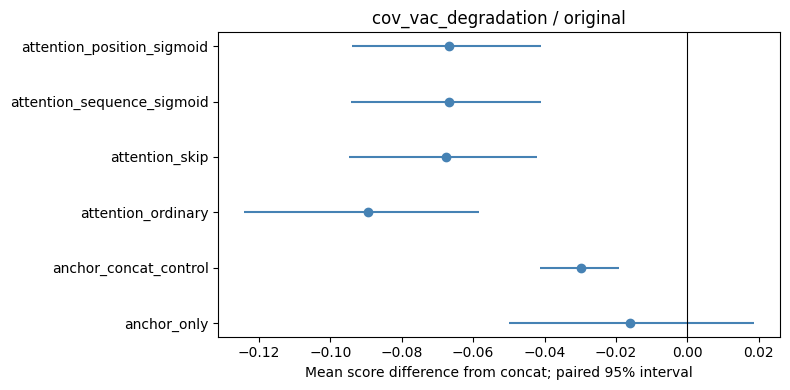

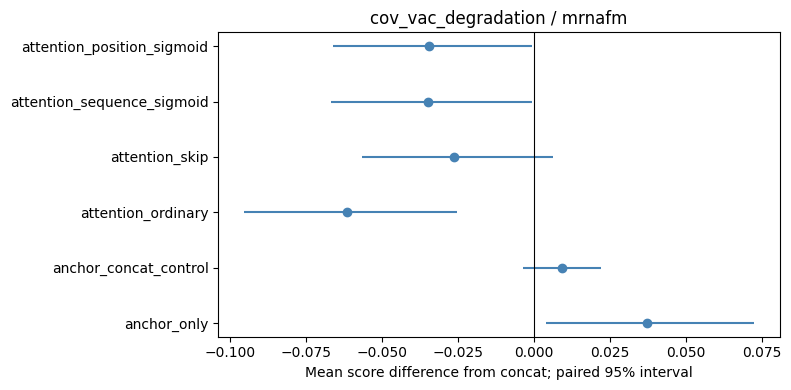

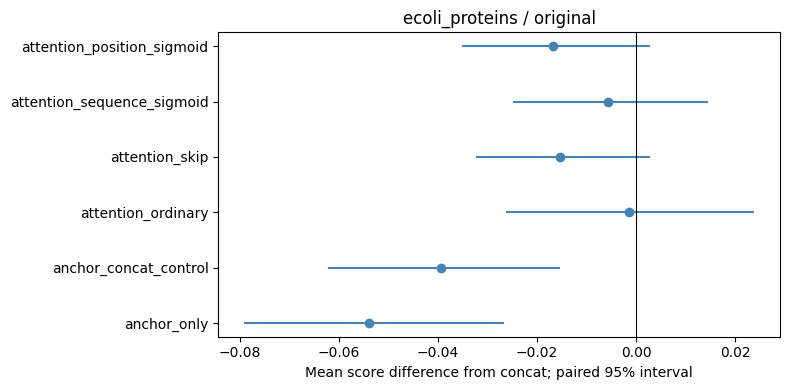

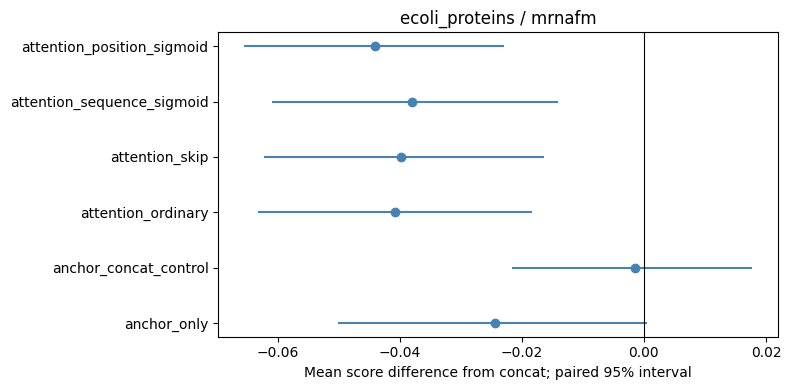

In [21]:
if report is not None:
    summaries = pd.DataFrame(report["summary"])
    intervals = pd.DataFrame(report["paired_intervals"])
    display(summaries)
    display(intervals)
    for (benchmark, bundle), rows in summaries.groupby(["benchmark", "bundle"], sort=False):
        compared = intervals[(intervals["benchmark"] == benchmark) & (intervals["bundle"] == bundle)]
        compared = compared.set_index("comparison").loc[[f"{model} minus concat" for model in rows["model"]]]
        positions = np.arange(len(rows))
        fig, ax = plt.subplots(figsize=(8, 4))
        ax.hlines(positions, compared["ci_low"], compared["ci_high"], color="steelblue")
        ax.scatter(compared["difference"], positions, color="steelblue")
        ax.set_yticks(positions, rows["model"])
        ax.axvline(0, color="black", linewidth=0.8)
        ax.set(title=f"{benchmark} / {bundle}", xlabel="Mean score difference from concat; paired 95% interval")
        fig.tight_layout()
        plt.show()

### Read gate variation and contribution scales

The plots read the saved CPU summary of Newton's per-example diagnostics. Each transcript contributes equally. Between-transcript quartiles describe the distribution of mean weights. For positional gates, the within-transcript standard deviation and range describe how much the weights change along one sequence. [Saved diagnostic distributions](results/anchor_cross_attention_v1/reports/gate-distributions-v2.json)

The norm table compares the sizes of the anchor and the auxiliary updates. The update-to-anchor ratio is calculated within each transcript before taking quartiles. Rows with a zero denominator are counted separately. A large update can reinforce or oppose the anchor, so its magnitude alone does not predict whether it helps.

The diagnostic rows identify the validation-selected modality. Where the model has sigmoid gates, their total weight can vary. Use the paired prediction differences to judge whether a gated update helped. The gate values describe how the trained model routed its inputs.

The [attention-interpretation source](../../docs/sources.md#jain-and-wallace-attention-is-not-explanation) motivates this distinction between weights and explanatory evidence; it does not establish a universal rule for every architecture or a biological mechanism.

In [22]:
def summarize_saved_gates():
    entries = [entry for entry in PANEL if entry["variant"] in experiment.SEQUENCE_VARIANTS
               or entry["variant"] == "position_sigmoid" or entry["variant"] in experiment.ATTENTION_VARIANTS]
    requests = [(benchmark, bundle, entry, seed) for benchmark in ACTIVE_BENCHMARKS
                for bundle in BUNDLES for entry in entries for seed in TRAINING_SEEDS]
    missing = [str(diagnostic_stem(b, c, e["key"], s)) for b, c, e, s in requests
               if not Path(str(diagnostic_stem(b, c, e["key"], s)) + ".json").is_file()]
    if missing:
        return None, missing
    report = {"schema": "controlled-gate-distributions-v2", "seeds": list(TRAINING_SEEDS),
              "sources": {},
              "analysis_source_sha256": hashlib.sha256(Path(experiment.__file__).read_bytes()).hexdigest(),
              "summary_rule": "equal-transcript means; within-row population SD/range; between-row quartiles",
              "summary": [], "positional_variation": [], "norm_summary": [],
              "update_anchor_ratios": [], "weight_mass": [], "diagnostic_status": []}
    for benchmark, bundle, entry, seed in requests:
        stem = diagnostic_stem(benchmark, bundle, entry["key"], seed)
        record, arrays = experiment.read_diagnostics(stem)
        result, fit_file = fit_source(benchmark, bundle, entry, seed)
        if result is None or record["identity"]["fit_sha256"] != hashlib.sha256(fit_file.read_bytes()).hexdigest():
            raise ValueError("Diagnostics do not identify the saved comparison fit.")
        for path in (fit_file, Path(str(stem) + ".json"), Path(str(stem) + ".npz")):
            source, checksum = source_record(path)
            report["sources"][source] = checksum
        choice = selected_anchor(benchmark, bundle)
        if choice is None:
            raise FileNotFoundError("Saved gate interpretation requires the fixed validation selection.")
        selection = RESULTS_ROOT / benchmark / bundle / "anchor-selection.json"
        source, checksum = source_record(selection)
        report["sources"][source] = checksum
        context = {"benchmark": benchmark, "bundle": bundle, "model": entry["key"], "seed": seed,
                   "selected single modality": choice["modality"]}
        measured = experiment.summarize_diagnostics(record, arrays)
        for quantity in ("summary", "positional_variation", "norm_summary", "update_anchor_ratios", "weight_mass"):
            report[quantity].extend({**context, **row} for row in measured[quantity])
        report["diagnostic_status"].append({**context, "norm status": measured["norm_status"],
                                             "temperature": measured["temperature"]})
    return report, []


In [23]:
GATE_REPORT_PATH = RESULTS_ROOT / "reports" / "gate-distributions-v2.json"
if RUN_ANALYSIS:
    gate_report, missing_diagnostics = summarize_saved_gates()
    if gate_report is None:
        print(f"Gate-distribution analysis held: {len(missing_diagnostics)} missing diagnostic records; no inference started.")
    elif GATE_REPORT_PATH.is_file():
        if json.loads(GATE_REPORT_PATH.read_text(encoding="utf-8")) != gate_report:
            raise ValueError("A different completed gate report exists; preserve it.")
    else:
        correction_experiment._publish(GATE_REPORT_PATH, gate_report)
else:
    legacy_report = RESULTS_ROOT / "reports" / "gate-distributions.json"
    read_path = GATE_REPORT_PATH if GATE_REPORT_PATH.is_file() else legacy_report
    gate_report = json.loads(read_path.read_text(encoding="utf-8")) if read_path.is_file() else None
    if gate_report is not None and read_path == legacy_report:
        print("Historical gate report: positional variation and contribution norms were not summarized.")
if gate_report is not None:
    verify_report_sources(gate_report)

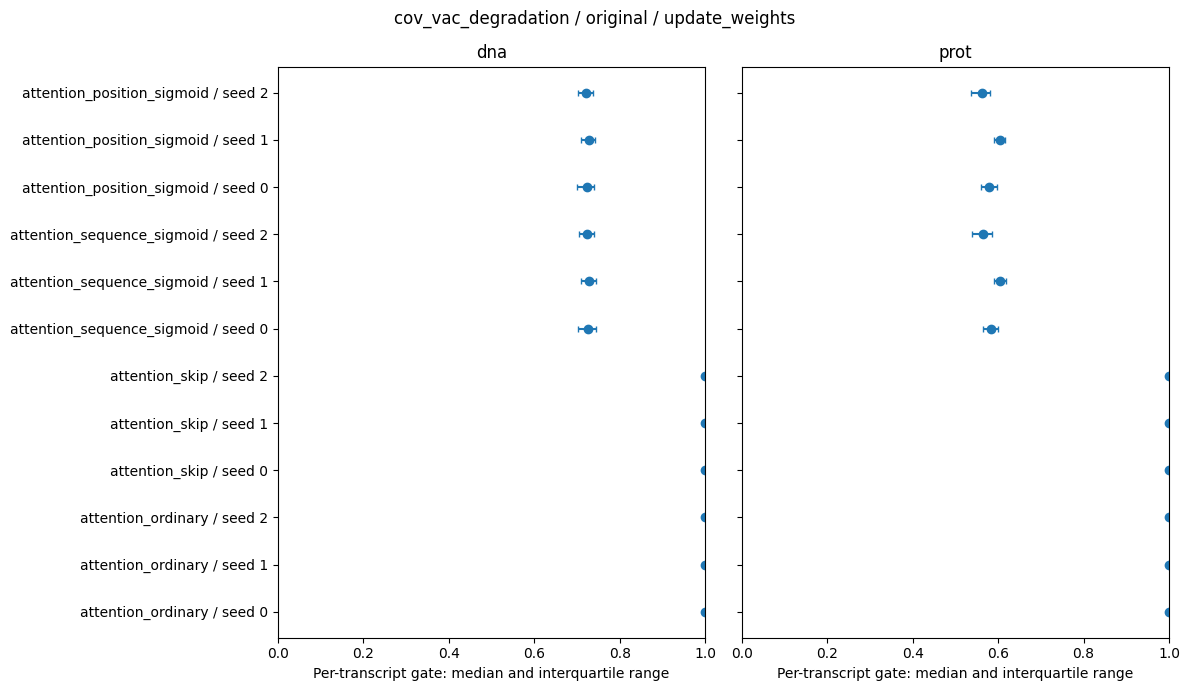

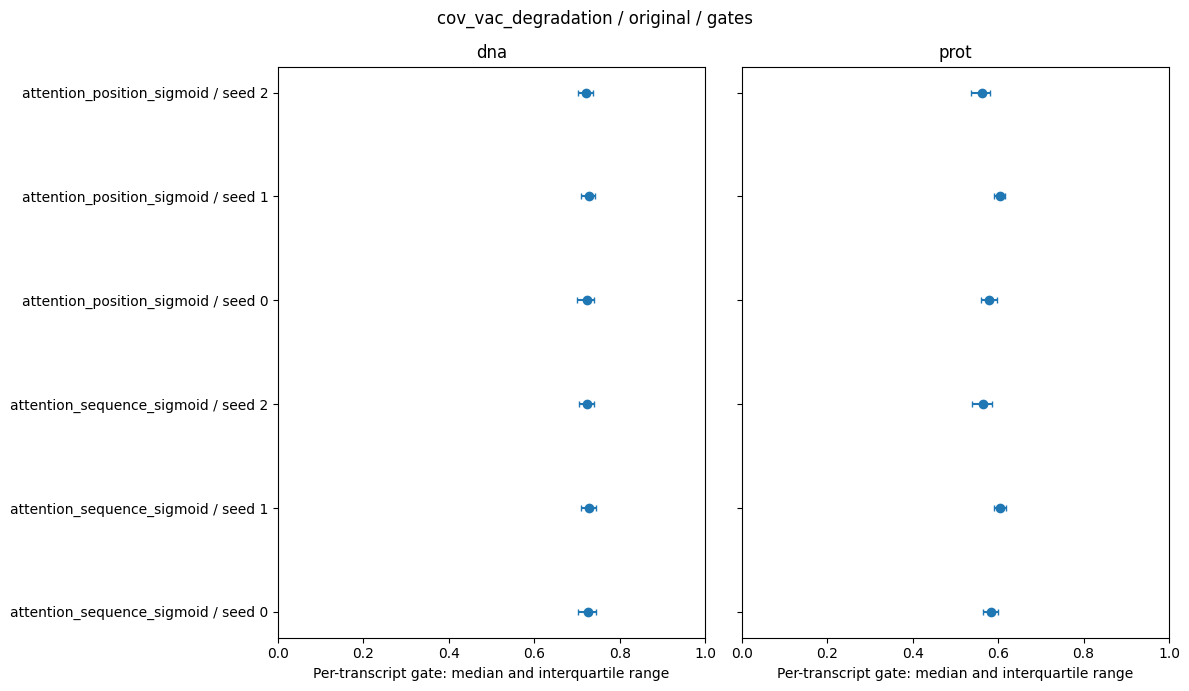

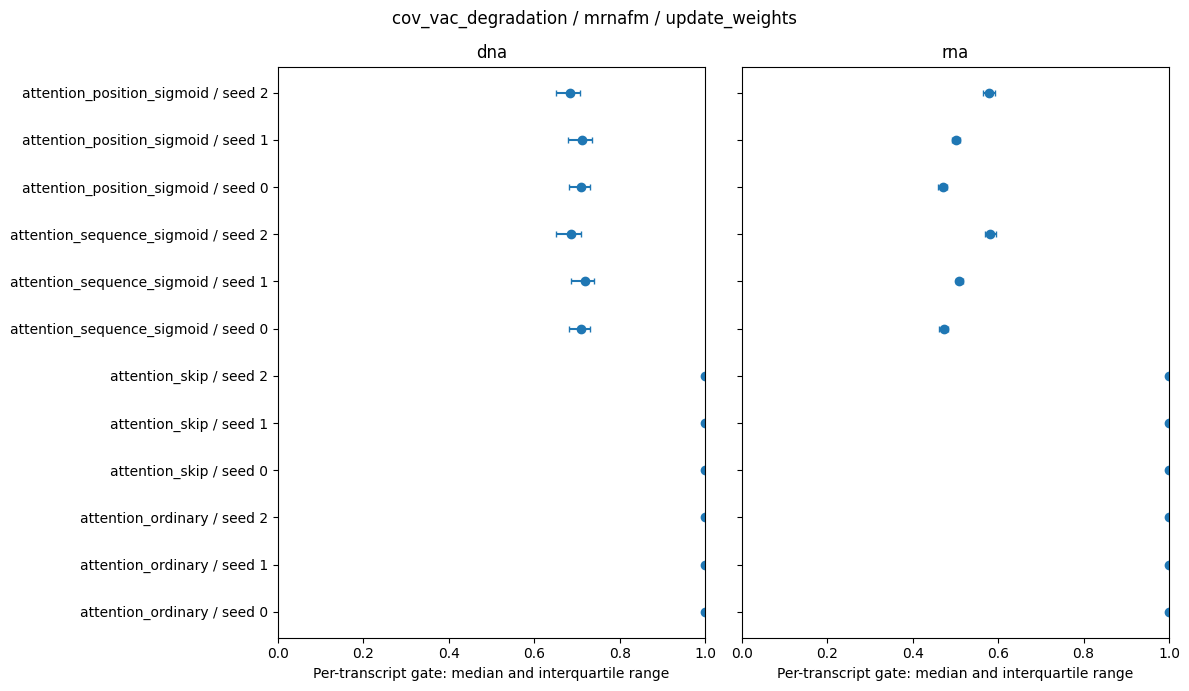

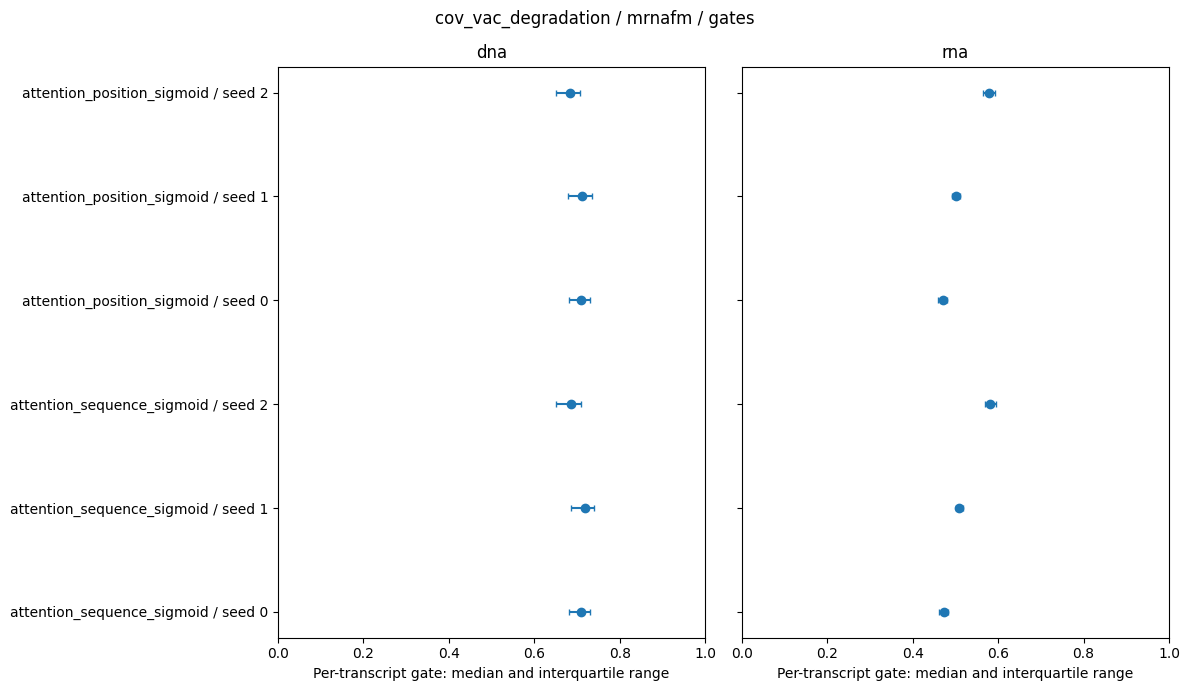

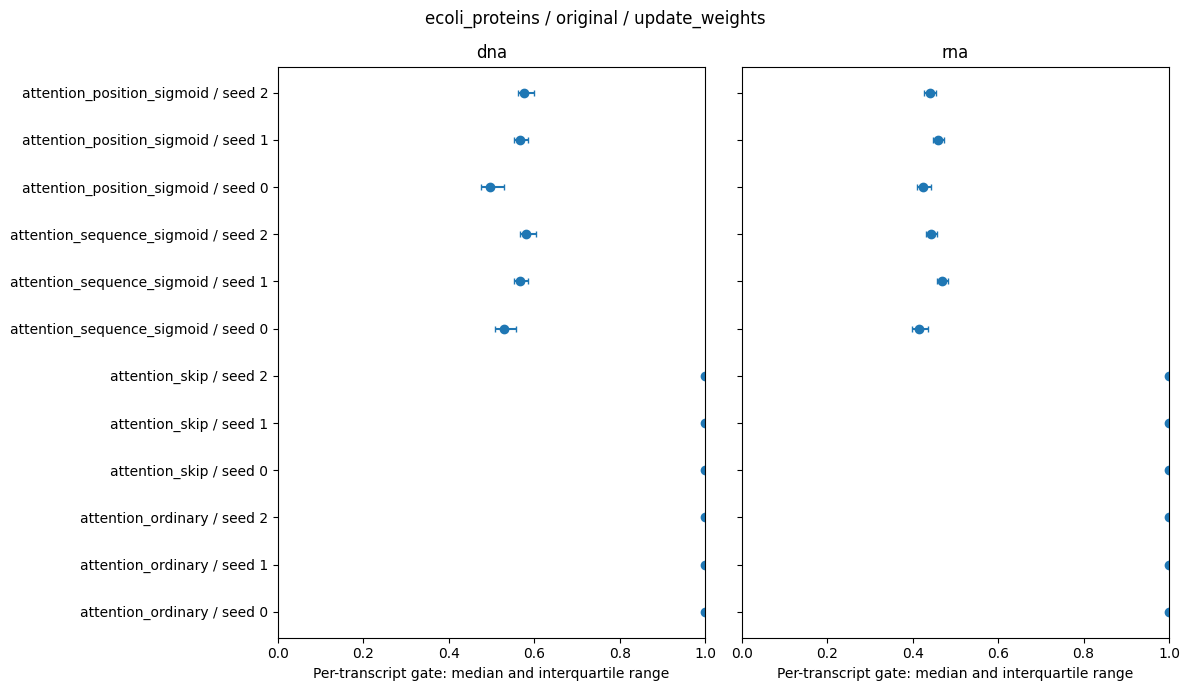

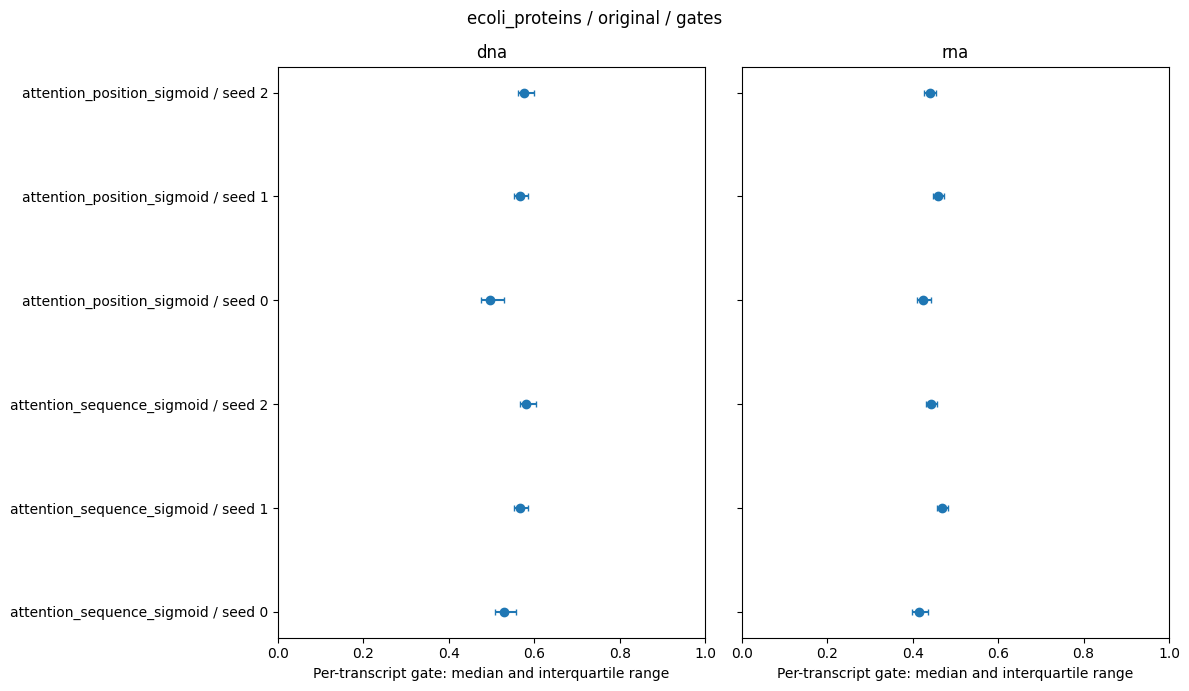

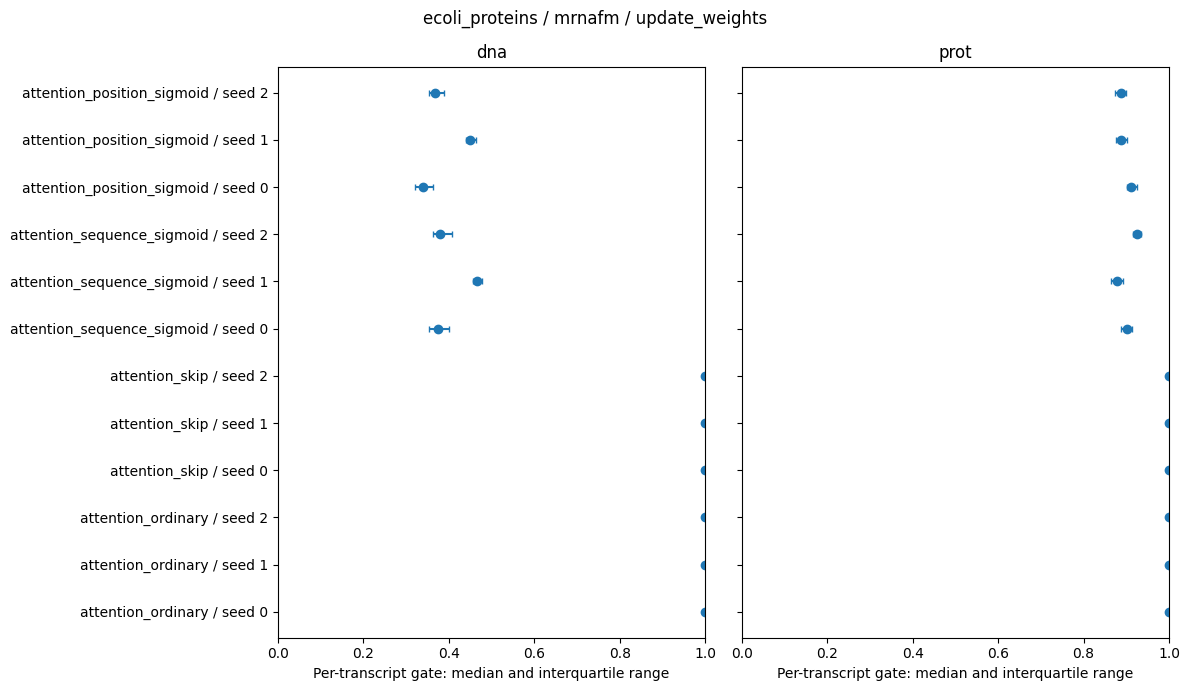

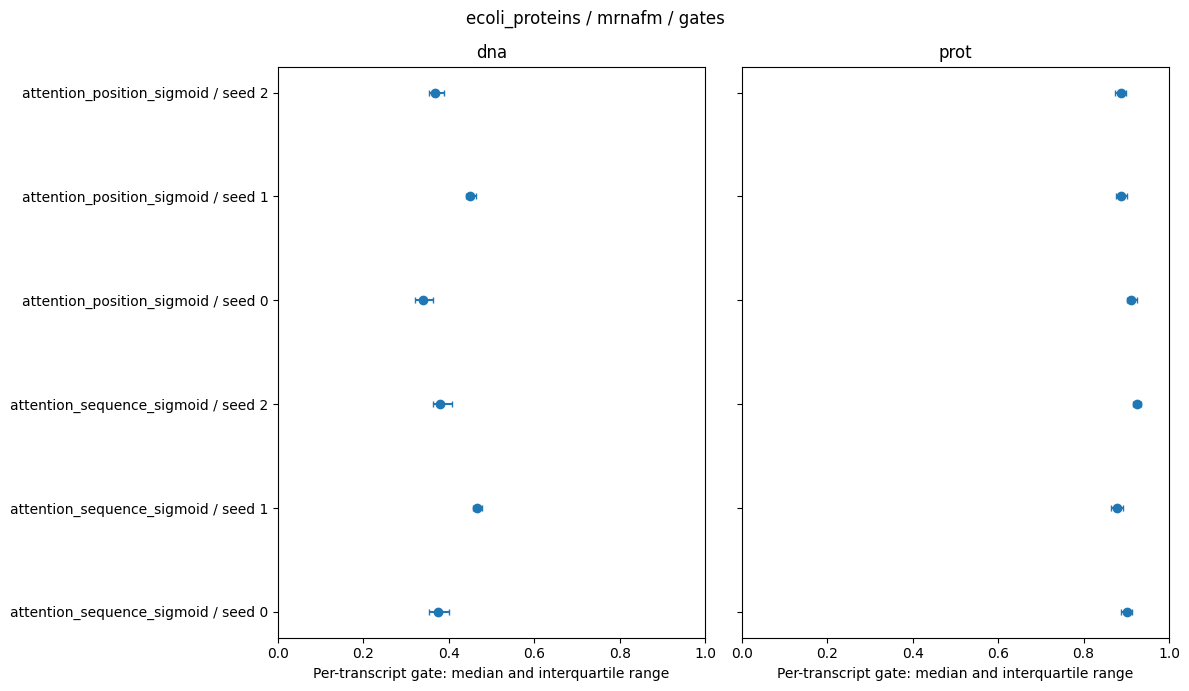

In [24]:
if gate_report is not None:
    gate_table = pd.DataFrame(gate_report["summary"])
    for (benchmark, bundle, quantity), group in gate_table.groupby(["benchmark", "bundle", "quantity"], sort=False):
        modalities = group["modality"].drop_duplicates().tolist()
        fig, axes = plt.subplots(1, len(modalities), figsize=(12, 7), sharey=True, squeeze=False)
        for ax, modality in zip(axes[0], modalities):
            rows = group.loc[group["modality"] == modality]
            labels = rows["model"] + " / seed " + rows["seed"].astype(str)
            ax.errorbar(rows["median"], labels,
                        xerr=[rows["median"] - rows["q25"], rows["q75"] - rows["median"]],
                        fmt="o", capsize=2)
            ax.set(title=modality, xlabel="Per-transcript gate: median and interquartile range", xlim=(0, 1))
        fig.suptitle(f"{benchmark} / {bundle} / {quantity}")
        fig.tight_layout()
        plt.show()

Within-transcript positional variation; median across transcripts, not an interval.


,benchmark,bundle,modality,model,quantity,seed,selected single modality,transcripts,within_row_range,within_row_sd
0,cov_vac_degradation,original,dna,attention_ordinary,update_weights,0,rna,400,0.000000,0.000000
1,cov_vac_degradation,original,prot,attention_ordinary,update_weights,0,rna,400,0.000000,0.000000
2,cov_vac_degradation,original,dna,attention_ordinary,update_weights,1,rna,400,0.000000,0.000000
3,cov_vac_degradation,original,prot,attention_ordinary,update_weights,1,rna,400,0.000000,0.000000
4,cov_vac_degradation,original,dna,attention_ordinary,update_weights,2,rna,400,0.000000,0.000000
...,...,...,...,...,...,...,...,...,...,...
115,ecoli_proteins,mrnafm,prot,attention_position_sigmoid,update_weights,1,rna,712,0.161416,0.012692
116,ecoli_proteins,mrnafm,dna,attention_position_sigmoid,gates,2,rna,712,0.080058,0.008282
117,ecoli_proteins,mrnafm,prot,attention_position_sigmoid,gates,2,rna,712,0.099968,0.008759
118,ecoli_proteins,mrnafm,dna,attention_position_sigmoid,update_weights,2,rna,712,0.080058,0.008282


Sum of modality weights: sequence means, then transcript quartiles; sigmoid mass need not equal one.


,benchmark,bundle,median,model,q25,q75,quantity,seed,selected single modality,transcripts
0,cov_vac_degradation,original,2.000000,attention_ordinary,2.000000,2.000000,update_weights,0,rna,400
1,cov_vac_degradation,original,2.000000,attention_ordinary,2.000000,2.000000,update_weights,1,rna,400
2,cov_vac_degradation,original,2.000000,attention_ordinary,2.000000,2.000000,update_weights,2,rna,400
3,cov_vac_degradation,original,2.000000,attention_skip,2.000000,2.000000,update_weights,0,rna,400
4,cov_vac_degradation,original,2.000000,attention_skip,2.000000,2.000000,update_weights,1,rna,400
...,...,...,...,...,...,...,...,...,...,...
67,ecoli_proteins,mrnafm,1.252328,attention_position_sigmoid,1.238852,1.270271,update_weights,0,rna,712
68,ecoli_proteins,mrnafm,1.339390,attention_position_sigmoid,1.319367,1.360288,gates,1,rna,712
69,ecoli_proteins,mrnafm,1.339390,attention_position_sigmoid,1.319367,1.360288,update_weights,1,rna,712
70,ecoli_proteins,mrnafm,1.254418,attention_position_sigmoid,1.240232,1.270935,gates,2,rna,712


Mean real-position Euclidean norms: transcript quartiles, not biological importance.


,benchmark,bundle,median,modality,model,q25,q75,quantity,seed,selected single modality,transcripts
0,cov_vac_degradation,original,13.768362,rna,attention_ordinary,13.365489,14.051358,anchor_norm,0,rna,400
1,cov_vac_degradation,original,1.436129,dna,attention_ordinary,1.108249,1.967331,raw_update_norms,0,rna,400
2,cov_vac_degradation,original,1.736756,prot,attention_ordinary,1.611620,1.966500,raw_update_norms,0,rna,400
3,cov_vac_degradation,original,1.436129,dna,attention_ordinary,1.108249,1.967331,update_norms,0,rna,400
4,cov_vac_degradation,original,1.736756,prot,attention_ordinary,1.611620,1.966500,update_norms,0,rna,400
...,...,...,...,...,...,...,...,...,...,...,...
283,ecoli_proteins,mrnafm,2.131078,dna,attention_position_sigmoid,2.046134,2.239455,raw_update_norms,2,rna,712
284,ecoli_proteins,mrnafm,1.976454,prot,attention_position_sigmoid,1.812966,2.241191,raw_update_norms,2,rna,712
285,ecoli_proteins,mrnafm,0.787513,dna,attention_position_sigmoid,0.767894,0.815900,update_norms,2,rna,712
286,ecoli_proteins,mrnafm,1.750335,prot,attention_position_sigmoid,1.592220,1.983091,update_norms,2,rna,712


Attention update / anchor norm: within-transcript ratios, then transcript quartiles.


,benchmark,bundle,median,modality,model,q25,q75,quantity,seed,selected single modality,transcripts,undefined_rows
0,cov_vac_degradation,original,0.105050,dna,attention_ordinary,0.080793,0.143205,raw_update_norms / anchor_norm,0,rna,400,0
1,cov_vac_degradation,original,0.127773,prot,attention_ordinary,0.117552,0.144492,raw_update_norms / anchor_norm,0,rna,400,0
2,cov_vac_degradation,original,0.105050,dna,attention_ordinary,0.080793,0.143205,update_norms / anchor_norm,0,rna,400,0
3,cov_vac_degradation,original,0.127773,prot,attention_ordinary,0.117552,0.144492,update_norms / anchor_norm,0,rna,400,0
4,cov_vac_degradation,original,0.094390,dna,attention_ordinary,0.073647,0.133904,raw_update_norms / anchor_norm,1,rna,400,0
...,...,...,...,...,...,...,...,...,...,...,...,...
187,ecoli_proteins,mrnafm,0.343566,prot,attention_position_sigmoid,0.318426,0.396997,update_norms / anchor_norm,1,rna,712,0
188,ecoli_proteins,mrnafm,0.390515,dna,attention_position_sigmoid,0.371838,0.410168,raw_update_norms / anchor_norm,2,rna,712,0
189,ecoli_proteins,mrnafm,0.359886,prot,attention_position_sigmoid,0.328139,0.408535,raw_update_norms / anchor_norm,2,rna,712,0
190,ecoli_proteins,mrnafm,0.143695,dna,attention_position_sigmoid,0.140054,0.148660,update_norms / anchor_norm,2,rna,712,0


Recorded norm availability and softmax temperature.


,benchmark,bundle,model,norm status,seed,selected single modality,temperature
0,cov_vac_degradation,original,attention_ordinary,recorded,0,rna,None
1,cov_vac_degradation,original,attention_ordinary,recorded,1,rna,None
2,cov_vac_degradation,original,attention_ordinary,recorded,2,rna,None
3,cov_vac_degradation,original,attention_skip,recorded,0,rna,None
4,cov_vac_degradation,original,attention_skip,recorded,1,rna,None
5,cov_vac_degradation,original,attention_skip,recorded,2,rna,None
6,cov_vac_degradation,original,attention_sequence_sigmoid,recorded,0,rna,None
7,cov_vac_degradation,original,attention_sequence_sigmoid,recorded,1,rna,None
8,cov_vac_degradation,original,attention_sequence_sigmoid,recorded,2,rna,None
9,cov_vac_degradation,original,attention_position_sigmoid,recorded,0,rna,None


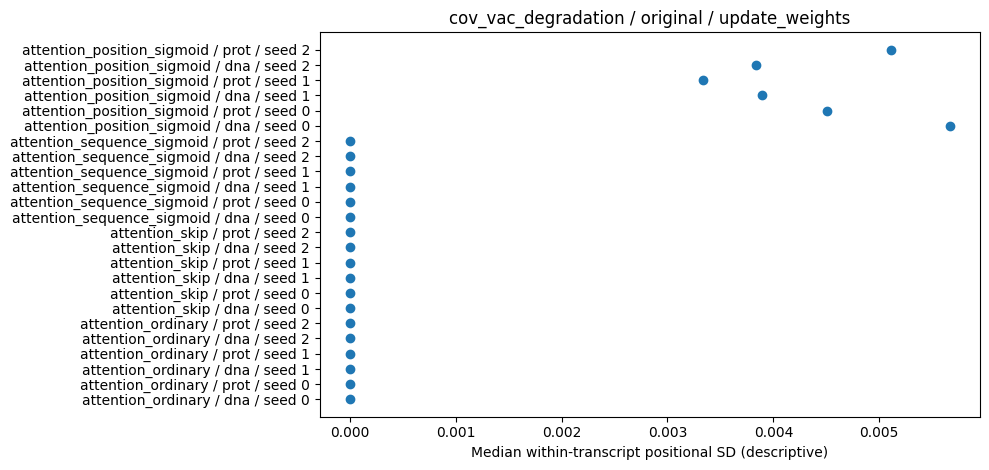

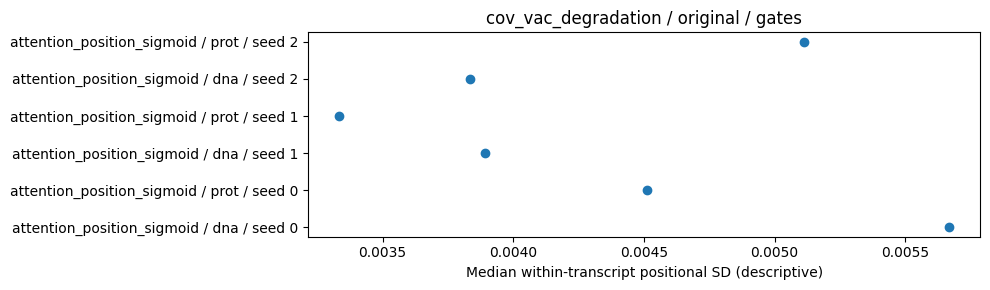

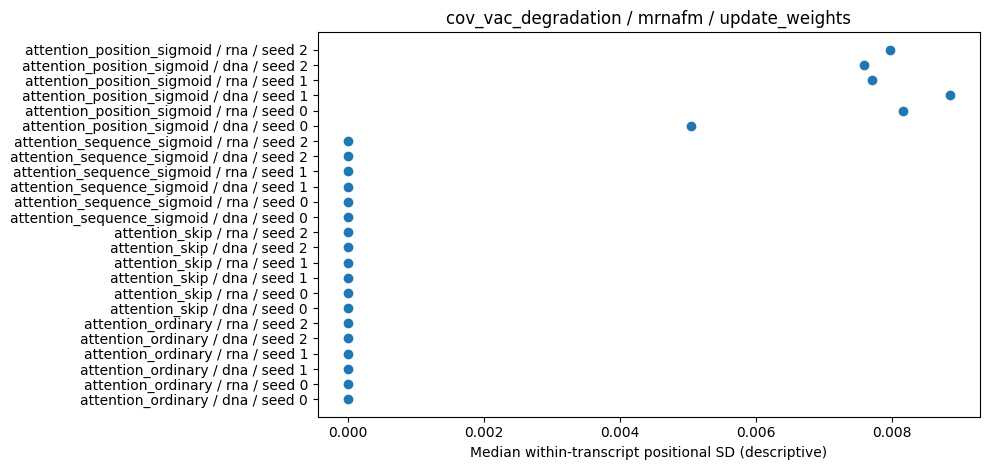

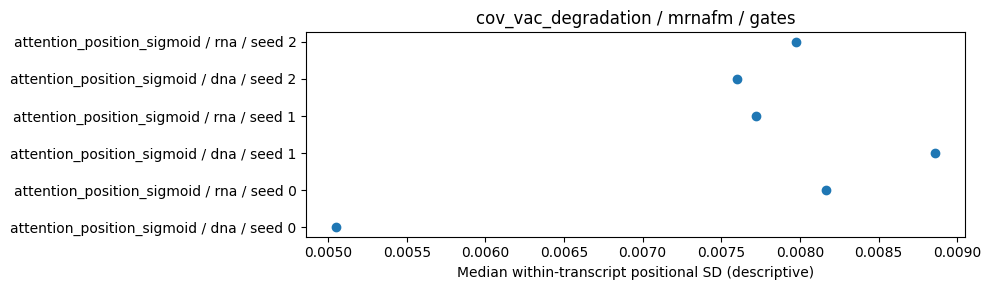

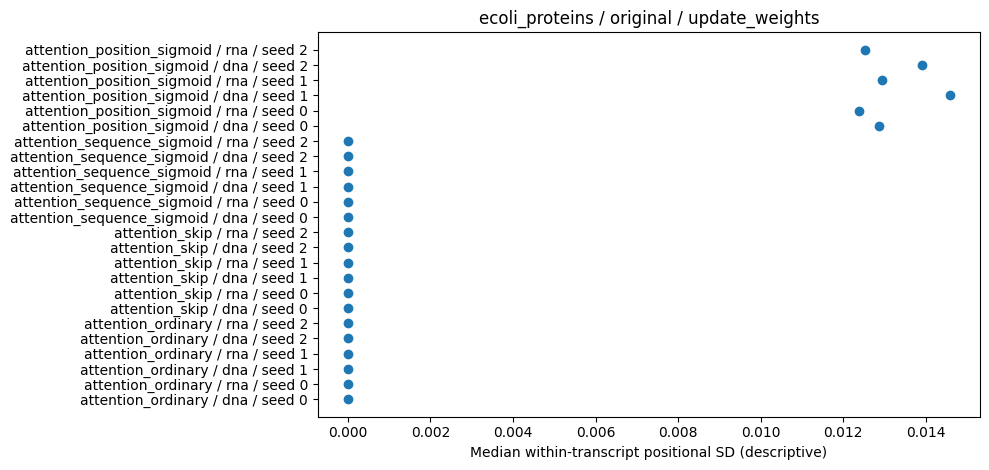

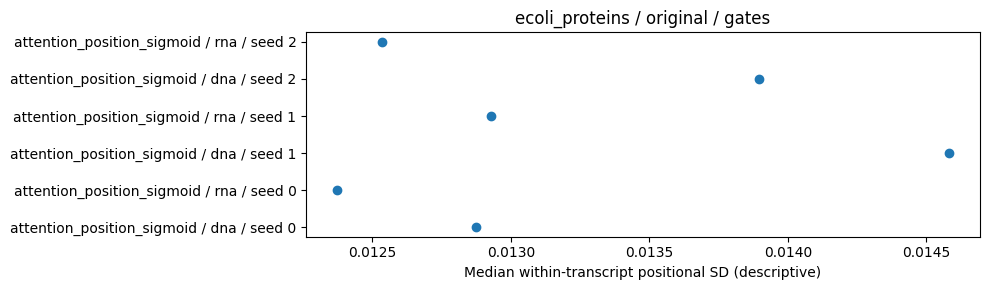

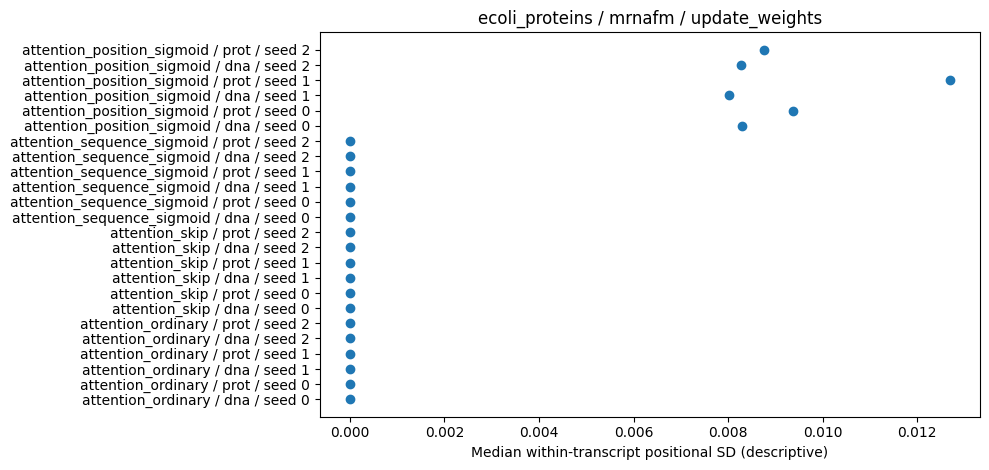

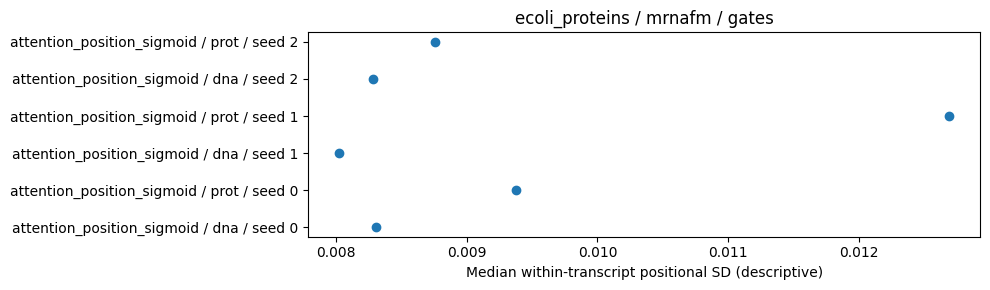

In [25]:
if gate_report is not None:
    for key, explanation in (
        ("positional_variation", "Within-transcript positional variation; median across transcripts, not an interval."),
        ("weight_mass", "Sum of modality weights: sequence means, then transcript quartiles; sigmoid mass need not equal one."),
        ("norm_summary", "Mean real-position Euclidean norms: transcript quartiles, not biological importance."),
        ("update_anchor_ratios", "Attention update / anchor norm: within-transcript ratios, then transcript quartiles."),
        ("diagnostic_status", "Recorded norm availability and softmax temperature."),
    ):
        print(explanation)
        rows = gate_report.get(key, [])
        if rows:
            display(pd.DataFrame(rows))
        else:
            print("Unavailable in this saved report; no inference or analysis started.")
    variation = pd.DataFrame(gate_report.get("positional_variation", []))
    if not variation.empty:
        for (benchmark, bundle, quantity), rows in variation.groupby(["benchmark", "bundle", "quantity"], sort=False):
            fig, ax = plt.subplots(figsize=(10, max(3, len(rows) * .2)))
            labels = rows["model"] + " / " + rows["modality"] + " / seed " + rows["seed"].astype(str)
            ax.scatter(rows["within_row_sd"], labels)
            ax.set(title=f"{benchmark} / {bundle} / {quantity}",
                   xlabel="Median within-transcript positional SD (descriptive)")
            fig.tight_layout()
            plt.show()


---

## What this can establish

On E. coli, sequence-gated attention exceeded the matched **local nonlinear mixer** by 3.37 percentage points with the original encoders (95% paired interval +1.22 to +5.57). With the mRNA-FM replacement the difference reversed to −3.65 points (−6.37 to −0.89). Even for the original encoders, the difference against **simple concatenation** was −0.56 points and the interval included zero. The choice of RNA encoder and the choice of baseline both affect the conclusion.

On CoV-Vac, the same sequence-gated attention model scored below the local mixer in both encoder combinations. The diagnostic plots show how much the model changed its projected anchor. Determining which biological features caused a predictive difference would require a separate intervention.